# Potential flow past a cylinder in a channel: two primal problems

Companion notebook to *Variational Methods in Computational Mechanics* (S. Vidoli),
Example "Potential Flow Past a Cylinder in a Channel".

An inviscid, incompressible fluid flows with mean velocity $U$ along a channel of width $2H$ past a cylinder of
radius $a$ on its axis. The flow is irrotational, $\mathbf{v} = \nabla\phi$, and by symmetry we compute on the
quarter domain $\Omega_+ = \{0 < x < L,\ 0 < y < H,\ x^2 + y^2 > a^2\}$. The velocity potential minimizes
$$\mathcal{E}_+(\phi) = \frac12\int_{\Omega_+}|\nabla\phi|^2\,dx - U\int_0^H \phi(L,y)\,dy,
  \qquad \phi = 0 \ \text{on } x = 0 ,$$
and every other boundary condition (walls, axis, cylinder, outlet) is natural.

The same flow can be described by the **stream function** $\psi$, with $v_x = \partial_y\psi$, $v_y = -\partial_x\psi$.
Any such field is divergence-free; the flow is irrotational when $\Delta\psi = 0$, and $\psi$ minimizes
$$\mathcal{T}(\psi) = \frac12\int_{\Omega_+}|\nabla\psi|^2\,dx, \qquad
  \psi = 0 \text{ on the axis and on the cylinder},\quad \psi = UH \text{ on the wall},\quad \psi = Uy \text{ at the outlet}:$$
among all divergence-free fields carrying the given flux, the irrotational one has the least kinetic energy
(Kelvin's theorem). Now the walls give *essential* conditions and the symmetry line $x = 0$ a natural one: the
roles are exchanged.

Both are ordinary minimum problems with the same stiffness matrix, and together they bracket the kinetic
energy $T = \frac12\int_{\Omega_+}|\mathbf v|^2$ (per unit density):
$$-\mathcal{E}_+(\phi_h) \;\le\; T \;\le\; \mathcal{T}(\psi_h).$$

**How to use it.** Run the cells in order (*Runtime → Run all* in Colab). Then change the parameters in the next
cell and run everything again.

In [1]:
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt

# ---------------------------------------------------------------- PARAMETERS
U, H    = 1.0, 1.0            # mean velocity and half-width of the channel
L       = 6.0                 # length of the quarter domain (outlet at x = L)
blockages = [0.05, 0.25, 0.5] # a/H, radius of the cylinder over half-width
n_plot  = 32                  # element sides along the quarter circle, for the plots
n_conv  = [8, 16, 32, 64]     # meshes of the convergence study
a_conv  = 0.5                 # blockage of the convergence study
# ---------------------------------------------------------------------------

## 1. Mesh, stiffness matrix, the two solutions

A structured mesh of linear triangles: near the cylinder, rays from the centre join the quarter circle to the
square $[0,H]^2$, with nodes graded towards the cylinder; downstream, a rectangular grid. Nothing in the
finite element code depends on the mesh being structured.

In [2]:
def make_mesh(a, n, grade=1.6):
    th = np.linspace(0, np.pi / 2, n + 1)
    t = np.linspace(0, 1, n + 1)**grade
    ox = np.where(th <= np.pi / 4, H, H / np.tan(np.maximum(th, 1e-30))); ox[-1] = 0.0
    oy = np.where(th <= np.pi / 4, H * np.tan(th), H)
    cx, cy = a * np.cos(th), a * np.sin(th); cx[-1] = 0.0
    X, A = [], np.zeros((n + 1, n + 1), int)          # A[j, i]: ring j, ray i
    for j in range(n + 1):
        for i in range(n + 1):
            A[j, i] = len(X); X.append(((1 - t[j]) * cx[i] + t[j] * ox[i], (1 - t[j]) * cy[i] + t[j] * oy[i]))
    yR = [X[A[n, i]][1] for i in range(n // 2 + 1)]
    nx = max(2, round((L - H) / (H / (n // 2))))
    xs = H + (L - H) * np.linspace(0, 1, nx + 1)
    B = np.zeros((nx + 1, n // 2 + 1), int)
    for k in range(nx + 1):
        for i in range(n // 2 + 1):
            if k == 0: B[k, i] = A[n, i]
            else: B[k, i] = len(X); X.append((xs[k], yR[i]))
    T = []
    for M, (r, c) in ((A, (n, n)), (B, (nx, n // 2))):
        for j in range(r):
            for i in range(c):
                p, q, s_, u_ = M[j, i], M[j + 1, i], M[j + 1, i + 1], M[j, i + 1]
                T += [(p, q, s_), (p, s_, u_)]
    X, T = np.array(X), np.array(T)
    d, e = X[T[:, 1]] - X[T[:, 0]], X[T[:, 2]] - X[T[:, 0]]
    neg = d[:, 0] * e[:, 1] - d[:, 1] * e[:, 0] < 0
    T[neg] = T[neg][:, [0, 2, 1]]
    nodes = dict(sym=A[:, n],                                  # x = 0, a < y < H
                 arc=A[0, :], axis=np.r_[A[:, 0], B[1:, 0]],
                 wall=np.r_[A[n, n // 2:], B[1:, n // 2]], outlet=B[nx, :])
    return X, T, th, nodes

def stiffness(X, T):
    """Assemble K_ij = int grad(phi_i).grad(phi_j) for linear triangles."""
    I, J, V = [], [], []
    for tri in T:
        Mx = np.c_[np.ones(3), X[tri]]
        G = np.linalg.inv(Mx)[1:]                               # gradients of the three hats
        Ke = 0.5 * abs(np.linalg.det(Mx)) * G.T @ G
        I += list(np.repeat(tri, 3)); J += list(np.tile(tri, 3)); V += list(Ke.ravel())
    return sp.csr_matrix((V, (I, J)), shape=(len(X),) * 2)

def solve_dirichlet(K, f, fixed, values):
    """Minimize 1/2 u.Ku - f.u with u = values on the fixed nodes."""
    u = np.zeros(K.shape[0]); u[fixed] = values
    free = np.setdiff1d(np.arange(K.shape[0]), fixed)
    u[free] = spla.spsolve(K[free][:, free].tocsc(), f[free] - K[free][:, fixed] @ u[fixed])
    return u

def solve_flow(a, n):
    X, T, th, nd = make_mesh(a, n)
    K = stiffness(X, T)
    # potential: load U * int phi(L, y) dy (trapezoidal = exact for linear elements), phi = 0 on x = 0
    f = np.zeros(len(X)); yo = X[nd["outlet"], 1]
    for k in range(len(yo) - 1):
        h = yo[k + 1] - yo[k]; f[nd["outlet"][k]] += U * h / 2; f[nd["outlet"][k + 1]] += U * h / 2
    phi = solve_dirichlet(K, f, nd["sym"], 0.0)
    # stream function: psi = 0 on axis and cylinder, U*H on the wall, U*y at the outlet; no load
    fixed = np.unique(np.r_[nd["axis"], nd["arc"], nd["wall"], nd["outlet"]])
    vals = np.where(np.isin(fixed, nd["wall"]), U * H, 0.0)
    out = np.isin(fixed, nd["outlet"]); vals[out] = U * X[fixed[out], 1]
    psi = solve_dirichlet(K, np.zeros(len(X)), fixed, vals)
    E_phi = 0.5 * phi @ (K @ phi) - f @ phi
    T_psi = 0.5 * psi @ (K @ psi)
    # speed on the cylinder: there d(phi)/dn = 0, so |v| is the derivative of phi along the arc
    vt = np.gradient(phi[nd["arc"]], a * th, edge_order=2)
    return dict(X=X, T=T, phi=phi, psi=psi, E=E_phi, Tpsi=T_psi, th=th, vt=vt, N=len(X))

sols = {aH: solve_flow(aH * H, n_plot) for aH in blockages}
for aH, s in sols.items():
    print(f"a/H = {aH:4.2f}: {s['N']} nodes,  top speed |v|/U = {abs(s['vt'][-1]) / U:.3f},"
          f"  min Cp = {1 - (s['vt'][-1] / U)**2:.2f}")

a/H = 0.05: 2449 nodes,  top speed |v|/U = 1.997,  min Cp = -2.99
a/H = 0.25: 2449 nodes,  top speed |v|/U = 2.111,  min Cp = -3.46
a/H = 0.50: 2449 nodes,  top speed |v|/U = 2.590,  min Cp = -5.71


## 2. Equipotentials and streamlines

The two families of level lines are orthogonal: the streamlines $\psi = $ const are the paths of the fluid
particles, the equipotentials $\phi = $ const cross them at right angles. The quarter domain is reflected to show
the whole cylinder; the reflection uses the symmetry of the problem, it is not computed.

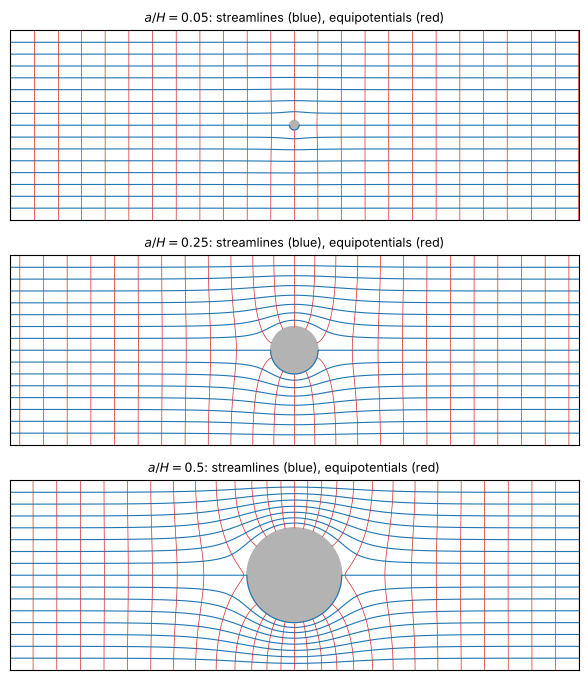

In [3]:
def mirror(s):
    X, T, phi, psi = s["X"], s["T"], s["phi"], s["psi"]
    Xs, Ts, Ps, Qs = [], [], [], []
    for sx, sy in ((1, 1), (-1, 1), (1, -1), (-1, -1)):
        Ts.append(T + len(X) * len(Xs)); Xs.append(X * [sx, sy])
        Ps.append(sx * phi); Qs.append(sy * psi)                # phi odd in x, psi odd in y
    return np.vstack(Xs), np.vstack(Ts), np.concatenate(Ps), np.concatenate(Qs)

fig, axs = plt.subplots(len(blockages), 1, figsize=(9, 2.3 * len(blockages)))
for ax, (aH, s) in zip(np.atleast_1d(axs), sols.items()):
    Xm, Tm, Pm, Qm = mirror(s)
    ax.tricontour(Xm[:, 0], Xm[:, 1], Tm, Qm, levels=np.linspace(-U * H, U * H, 17)[1:-1], colors="C0", linewidths=0.8, linestyles="solid")
    ax.tricontour(Xm[:, 0], Xm[:, 1], Tm, Pm, levels=np.arange(-L, L, 0.25 * H), colors="C3", linewidths=0.5, linestyles="solid")
    ax.add_patch(plt.Circle((0, 0), aH * H, color="0.7"))
    ax.set_xlim(-3 * H, 3 * H); ax.set_ylim(-H, H); ax.set_aspect("equal")
    ax.set_title(f"$a/H = {aH}$: streamlines (blue), equipotentials (red)", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## 3. Pressure on the cylinder

Bernoulli's theorem gives the pressure coefficient $C_p = 1 - |\mathbf v|^2/U^2$. On the cylinder
$\partial_n\phi = 0$, so the speed is the derivative of the potential along the circle, which we take from the
nodal values. The angle $\theta$ is measured from the rear stagnation point; by the symmetry of the problem the
front half is the mirror image, and the drag vanishes (d'Alembert's paradox).

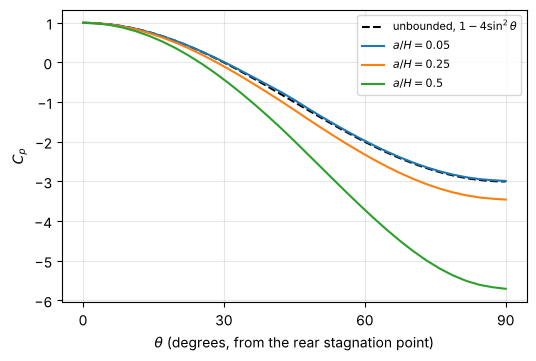

In [4]:
fig, ax = plt.subplots(figsize=(6, 3.8))
tt = np.linspace(0, np.pi / 2, 200)
ax.plot(np.degrees(tt), 1 - 4 * np.sin(tt)**2, "k--", label=r"unbounded, $1 - 4\sin^2\theta$")
for aH, s in sols.items():
    ax.plot(np.degrees(s["th"]), 1 - (s["vt"] / U)**2, label=f"$a/H = {aH}$")
ax.set_xlabel(r"$\theta$ (degrees, from the rear stagnation point)"); ax.set_ylabel("$C_p$")
ax.set_xticks([0, 30, 60, 90]); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.show()

The smallest cylinder follows the unbounded solution. As the cylinder fills the channel, the fluid must pass
through a narrower gap and accelerates: the suction at the top deepens, while the stagnation point keeps
$C_p = 1$.

## 4. Convergence, and two-sided bounds on the kinetic energy

The minimum of $\mathcal E_+$ is $-T$, and $\mathcal E_+(\phi_h) - \mathcal E_+(\phi) = \frac12\|\phi - \phi_h\|^2_a \ge 0$:
the potential underestimates the kinetic energy. The stream function minimizes $\mathcal T$ itself, and
overestimates it. The gap between the two bounds is a computable error estimate.

   n   nodes   top speed   -E(phi_h)    T(psi_h)       gap
   8     181      2.5916     3.24093     3.24889   7.96e-03
  16     649      2.5900     3.24561     3.24766   2.05e-03
  32    2449      2.5896     3.24683     3.24735   5.18e-04
  64    9505      2.5895     3.24714     3.24727   1.30e-04


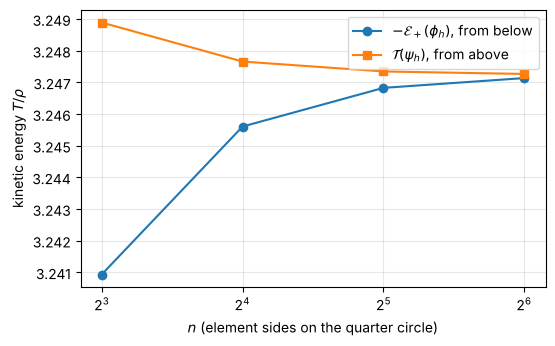

In [5]:
print("   n   nodes   top speed   -E(phi_h)    T(psi_h)       gap")
rows = []
for n in n_conv:
    s = solve_flow(a_conv * H, n)
    rows.append((n, -s["E"], s["Tpsi"]))
    print(f"{n:4d} {s['N']:7d}   {abs(s['vt'][-1]):9.4f}   {-s['E']:9.5f}   {s['Tpsi']:9.5f}   {s['Tpsi'] + s['E']:.2e}")
n_, lo, hi = map(np.array, zip(*rows))
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(n_, lo, "o-", label=r"$-\mathcal{E}_+(\phi_h)$, from below")
ax.plot(n_, hi, "s-", label=r"$\mathcal{T}(\psi_h)$, from above")
ax.set_xscale("log", base=2); ax.set_xlabel("$n$ (element sides on the quarter circle)")
ax.set_ylabel("kinetic energy $T/\\rho$"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

Halving the mesh size divides the gap by about four: both energies converge like $h^2$, the square of the
energy-norm error. (Strictly, the bounds hold for the meshed domain, where the circle is an inscribed polygon;
the two problems are solved on the same mesh, so the bracket is consistent.)

## Things to try
1. Move the outlet closer, `L = 2.0`: does the top speed change? How far downstream does the cylinder make
   itself felt?
2. Try `blockages = [0.8, 0.9]`: the gap between cylinder and wall becomes a nozzle. Compare the top speed with
   the one-dimensional estimate $U H/(H - a)$ from mass conservation.
3. Set `n_plot = 8` and look at $C_p$: where on the cylinder is the coarse mesh worst?
4. Remove the grading of the mesh (`grade=1.0` in `make_mesh`): how does the gap between the two bounds react?